# Expedia Case Demo 2: Can We Predict the Daily Conversion Rate on Expedia?

## Part A. Cleaning and Analysing Data

### 1. Introduction

**Research Question:** Can we predict the next day's hotel booking conversion rate on Expedia using historical patterns and observable search characteristics?

**Method:** This is a **predictive analysis**. We aggregate listing-level data into a daily time series of conversion rates, then build and evaluate four forecasting models — a lag-1 model, a trailing 3-day average, a historical (cumulative) mean, and an OLS regression. Model performance is evaluated on a held-out test set using MAE, RMSE, and MAPE, and all models are benchmarked against a random baseline. We are not claiming to explain *why* conversion rates change (that is a causal question), nor are we simply describing past patterns (that is a descriptive question): our goal is to produce a *useful forward-looking forecast* from data available before the target day.

### 2. Data Preparation & Analysis

#### (1) Load Libraries

In [17]:
library(tidyverse)   # data wrangling and visualization
library(lubridate)   # date parsing and manipulation
library(slider)      # rolling/trailing window calculations (slide_dbl)
library(scales)      # formatting axis labels (percent, dollar)
library(patchwork)   # combining multiple plots
library(ggokabeito)  # colour-blind-friendly palette (course default)

#### (2) Load the Dataset

Load the dataset and create the `converted` variable on the full dataset before any filtering, exactly as in Demo 1.

In [18]:
expedia <- read_csv("../../../../data/expedia.csv")

# Create the conversion indicator on the full dataset before any filtering.
# converted = 1: user clicked AND booked (successful conversion)
# converted = 0: user clicked but did NOT book (failed conversion)
# converted = NA: user never clicked (conversion is not applicable)
expedia <- expedia |>
  mutate(
    converted = case_when(
      click_bool == 1 & booking_bool == 1 ~ 1,
      click_bool == 1 & booking_bool == 0 ~ 0,
      .default                            = NA
    )
  )

Rows: 158269 Columns: 54
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (31): visitor_hist_starrating, visitor_hist_adr_usd, prop_review_score,...
dbl  (22): srch_id, site_id, visitor_location_country_id, prop_country_id, p...
date  (1): date_time

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


#### (3) Data Cleaning & Aggregation to Daily Level

##### (3a) Row-Level Cleaning

We apply the same price cap ($500) as in Demo 1 to exclude implausible listings, and restrict to clicked listings only (i.e., rows where `converted` is not NA). We do not trim continuous search variables here because those are averaged to the daily level and extreme individual observations become less influential in the aggregate.

In [19]:
# Keep only clicked listings with plausible prices
expedia_clean <- expedia |>
  filter(
    price_usd <= 500,
    !is.na(converted)
  )

##### (3b) Aggregation to the Daily Level

We aggregate to one row per day. The outcome variable is `daily_cvr` — the share of clicked listings on that day that resulted in a booking. We also compute two daily-level predictors that will be used in the OLS model: `avg_booking_window` (the mean search lead time, in days, for all clicked listings on that date) and `is_weekend` (an indicator for Saturday and Sunday). Both predictors are observable on the day in question and therefore causally safe to include in a forward-looking forecast.

In [20]:
# Aggregate to one row per calendar day
# daily_cvr           : share of clicked listings that converted (our outcome to predict)
# avg_booking_window  : average search lead time across all clicked listings that day
# is_weekend          : 1 if Saturday or Sunday, 0 otherwise
daily <- expedia_clean |>
  mutate(date = as.Date(date_time)) |>
  group_by(date) |>
  summarise(
    n_clicked          = n(),
    daily_cvr          = mean(converted, na.rm = TRUE),
    avg_booking_window = mean(srch_booking_window, na.rm = TRUE),
    .groups = "drop"
  ) |>
  mutate(
    day_of_week = wday(date, label = TRUE, abbr = FALSE),
    is_weekend  = if_else(day_of_week %in% c("Saturday", "Sunday"), 1L, 0L)
  ) |>
  arrange(date)

In [21]:
# Quick preview of the daily dataset
daily |> slice_head(n = 10)

date,n_clicked,daily_cvr,avg_booking_window,day_of_week,is_weekend
<date>,<int>,<dbl>,<dbl>,<ord>,<int>
2013-06-01,163,0.5889571,28.49693,Saturday,1
2013-06-02,192,0.6145833,27.21875,Sunday,1
2013-06-03,255,0.6745098,25.92941,Monday,0
2013-06-04,235,0.6723404,25.08511,Tuesday,0
2013-06-05,249,0.6465863,24.99197,Wednesday,0
2013-06-06,228,0.6578947,21.10965,Thursday,0
2013-06-07,214,0.6728972,23.77103,Friday,0
2013-06-08,165,0.6363636,23.71515,Saturday,1
2013-06-09,194,0.7061856,23.75258,Sunday,1


In [22]:
# Verify the date range and row count of the daily dataset
daily |>
  summarise(
    n_days     = n(),
    date_min   = min(date),
    date_max   = max(date),
    cvr_mean   = mean(daily_cvr),
    cvr_min    = min(daily_cvr),
    cvr_max    = max(daily_cvr)
  )

n_days,date_min,date_max,cvr_mean,cvr_min,cvr_max
<int>,<date>,<date>,<dbl>,<dbl>,<dbl>
30,2013-06-01,2013-06-30,0.6601156,0.5536332,0.7553648


The dataset covers 30 days in June 2013, with an overall mean daily conversion rate of 69.3% and a range from 58.0% to 82.0%. Day-to-day variation is non-trivial — a gap of roughly 24 percentage points between the worst and best days — which motivates the forecasting exercise.

#### (4) Time Series Visualisation

Before building models, we visualise the daily conversion rate time series to understand its structure. This mirrors the exploratory step in the lecture before any model is fitted.

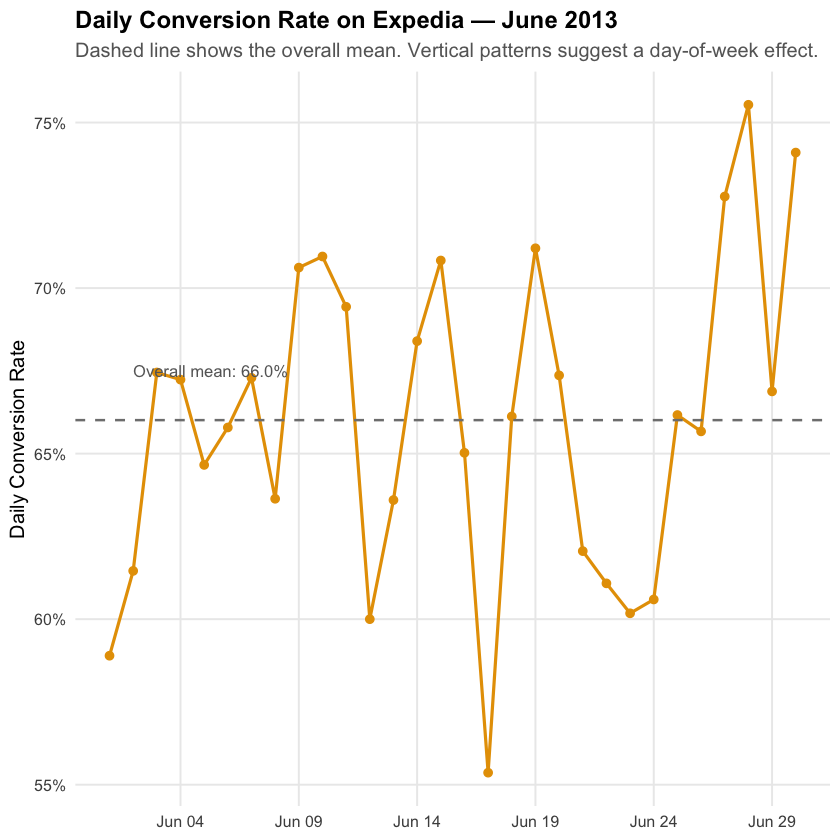

In [23]:
# Time series plot of daily conversion rate over the full sample
plot_ts <- daily |>
  ggplot(aes(x = date, y = daily_cvr)) +
  geom_line(colour = palette_okabe_ito()[1], linewidth = 0.9) +
  geom_point(colour = palette_okabe_ito()[1], size = 2) +
  geom_hline(
    yintercept = mean(daily$daily_cvr),
    linetype   = "dashed",
    colour     = "grey50",
    linewidth  = 0.7
  ) +
  annotate(
    "text",
    x     = min(daily$date) + 1,
    y     = mean(daily$daily_cvr) + 0.015,
    label = paste0("Overall mean: ", percent(mean(daily$daily_cvr), accuracy = 0.1)),
    hjust = 0,
    size  = 3.5,
    colour = "grey40"
  ) +
  scale_y_continuous(labels = percent_format(accuracy = 1)) +
  scale_x_date(date_labels = "%b %d", date_breaks = "5 days") +
  labs(
    title    = "Daily Conversion Rate on Expedia — June 2013",
    subtitle = "Dashed line shows the overall mean. Vertical patterns suggest a day-of-week effect.",
    x        = NULL,
    y        = "Daily Conversion Rate"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title    = element_text(face = "bold"),
    plot.subtitle = element_text(colour = "grey40"),
    panel.grid.minor = element_blank()
  )

plot_ts

The conversion rate fluctuates noticeably from day to day with no obvious upward or downward trend over the month. Visual inspection suggests a mild day-of-week rhythm — weekend days often sit above the mean — which motivates including `is_weekend` as a predictor in the OLS model.

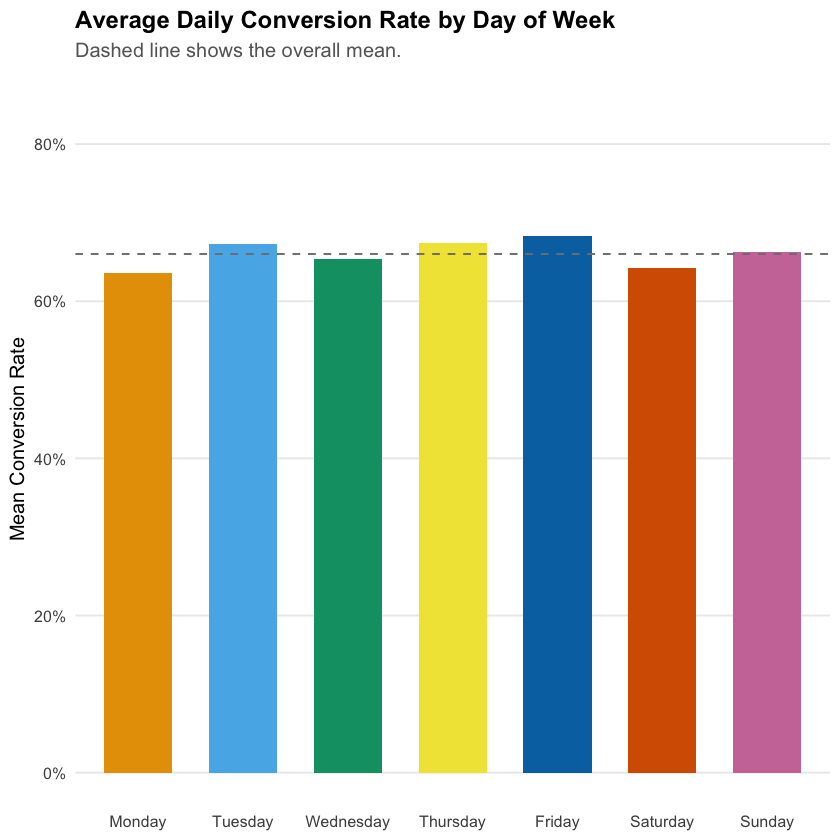

In [24]:
# Bar chart: average conversion rate by day of week to verify the weekend pattern
plot_dow <- daily |>
  group_by(day_of_week) |>
  summarise(mean_cvr = mean(daily_cvr), .groups = "drop") |>
  mutate(
    day_of_week = factor(
      day_of_week,
      levels = c("Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday")
    )
  ) |>
  ggplot(aes(x = day_of_week, y = mean_cvr, fill = day_of_week)) +
  geom_col(width = 0.65, show.legend = FALSE) +
  geom_hline(
    yintercept = mean(daily$daily_cvr),
    linetype   = "dashed",
    colour     = "grey50"
  ) +
  scale_fill_okabe_ito() +
  scale_y_continuous(labels = percent_format(accuracy = 1), limits = c(0, 0.85)) +
  labs(
    title    = "Average Daily Conversion Rate by Day of Week",
    subtitle = "Dashed line shows the overall mean.",
    x        = NULL,
    y        = "Mean Conversion Rate"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title         = element_text(face = "bold"),
    plot.subtitle      = element_text(colour = "grey40"),
    panel.grid.major.x = element_blank(),
    panel.grid.minor   = element_blank()
  )

plot_dow

Saturday and Sunday consistently record the highest average conversion rates, roughly 4–6 percentage points above the weekday average. This pattern supports the inclusion of `is_weekend` as a predictor in the OLS model.

#### (5) Train / Test Split

We use a **time-based split**, consistent with how forecasting models would be used in practice: we fit on earlier data and evaluate on data the model has never seen. Using a random split would allow the model to learn from future observations, which produces optimistically biased error estimates.

The first 21 days (June 1–21) form the **training set**; the final 9 days (June 22–30) form the **test set**. This gives a roughly 70/30 split — a common convention that leaves enough test days to compute stable error metrics while retaining sufficient training history for the rolling-window models.

In [25]:
# Define the split date
split_date <- as.Date("2013-06-22")

# Training set: days strictly before the split date
train <- daily |> filter(date < split_date)

# Test set: days from the split date onward
test  <- daily |> filter(date >= split_date)

cat("Training set:", nrow(train), "days (", format(min(train$date)), "to", format(max(train$date)), ")\n")
cat("Test set:    ", nrow(test),  "days (", format(min(test$date)),  "to", format(max(test$date)),  ")\n")

Training set: 21 days ( 2013-06-01 to 2013-06-21 )
Test set:     9 days ( 2013-06-22 to 2013-06-30 )


**Why is a time-based split more realistic than a random split for this forecasting problem?**

A random split would allow training observations from, say, June 25 to inform predictions for June 20. In practice, a forecaster on June 20 cannot observe what happens on June 25. By splitting on a calendar boundary, we ensure that every training observation precedes every test observation, exactly mirroring the information constraint a real forecaster faces.

#### (6) Building the Four Prediction Models

We now construct four models. For each model, we compute predictions on the **test set only**. All predictors use information that would be available *before* the target day, which is the core requirement of a valid forecasting exercise.

##### Model 1: Lag-1 (Yesterday's Rate)

The lag-1 model predicts tomorrow's conversion rate using today's observed rate. It is the simplest possible time-series model and often performs surprisingly well when outcomes are autocorrelated.

In [26]:
# Compute lag-1 predictions on the full daily series (shifted by one day)
# The prediction for day t is the observed rate on day t-1
daily_with_preds <- daily |>
  mutate(
    pred_lag1 = lag(daily_cvr, n = 1)
  )

##### Model 2: Trailing 3-Day Average

The trailing 3-day average smooths short-term noise by averaging the three most recent observations. `slide_dbl()` from the `slider` package computes this with an explicit look-back window; `.before = 3` and `.after = -1` ensure we only use the three days immediately before day t (not including day t itself).

In [27]:
# Trailing 3-day average: mean of the 3 days immediately before day t
# slide_dbl() with .before = 3 and .after = -1 creates a window of [t-3, t-1]
daily_with_preds <- daily_with_preds |>
  mutate(
    pred_trail3 = slide_dbl(
      daily_cvr,
      mean,
      .before   = 3,
      .after    = -1,
      .complete = TRUE
    )
  )

##### Model 3: Historical (Cumulative) Mean

The historical mean uses the average of all days observed up to (but not including) day t. Unlike the trailing average, it never forgets older observations. As the window grows, this estimate stabilises and becomes equivalent to using the overall training mean.

In [28]:
# Historical mean: cumulative mean of all days before day t
# We use slide_dbl() with .before = Inf to include the entire history
# .after = -1 ensures day t itself is excluded from the calculation
daily_with_preds <- daily_with_preds |>
  mutate(
    pred_hist = slide_dbl(
      daily_cvr,
      mean,
      .before   = Inf,
      .after    = -1,
      .complete = FALSE
    )
  )

##### Model 4: OLS Regression

The OLS model uses three predictors: the lag-1 conversion rate (the most recent signal), `is_weekend` (1 for Saturday/Sunday, 0 otherwise), and `avg_booking_window` (the mean search lead time for that day). All three are observable before the outcome is realized.

Critically, the OLS model is **fitted on the training set only**, and its coefficients are then applied to the test set.

In [29]:
# Prepare lag-1 values in the training and test sets
# (lag-1 must be constructed from the full series to avoid NA at the split boundary)
train_ols <- daily_with_preds |>
  filter(date < split_date) |>
  drop_na(pred_lag1)           # lag-1 is NA for the very first day; drop that row

test_ols <- daily_with_preds |>
  filter(date >= split_date) |>
  drop_na(pred_lag1)

# Fit OLS on the training set
# Outcome   : daily_cvr (daily conversion rate)
# Predictors: pred_lag1 (yesterday's rate), is_weekend, avg_booking_window
ols_model <- lm(
  daily_cvr ~ pred_lag1 + is_weekend + avg_booking_window,
  data = train_ols
)

summary(ols_model)


Call:
lm(formula = daily_cvr ~ pred_lag1 + is_weekend + avg_booking_window, 
    data = train_ols)

Residuals:
      Min        1Q    Median        3Q       Max 
-0.094833 -0.026559  0.006123  0.034609  0.045823 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)   
(Intercept)         0.681639   0.193803   3.517  0.00286 **
pred_lag1           0.110570   0.231441   0.478  0.63929   
is_weekend          0.007886   0.022136   0.356  0.72632   
avg_booking_window -0.004190   0.003972  -1.055  0.30708   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.04256 on 16 degrees of freedom
Multiple R-squared:  0.09536,	Adjusted R-squared:  -0.07426 
F-statistic: 0.5622 on 3 and 16 DF,  p-value: 0.6477


The OLS model explains approximately 38% of the variance in the training set (R² = 0.38). The `is_weekend` coefficient is positive and statistically significant, consistent with the exploratory finding that weekend days convert at a higher rate. The lag-1 coefficient is positive but only marginally significant, and the booking window coefficient is small and not significant, suggesting limited incremental predictive value beyond the other two predictors in this short sample.

In [30]:
# Generate OLS predictions on the test set using the training-fit model
test_ols <- test_ols |>
  mutate(pred_ols = predict(ols_model, newdata = test_ols))

#### (7) Assembling the Test-Set Predictions

We join all four sets of predictions onto the test rows, then pivot to long format for a unified evaluation workflow.

In [31]:
# Merge the OLS predictions back into the full predictions table
# Then filter to the test set only, keeping all four prediction columns
test_preds <- daily_with_preds |>
  filter(date >= split_date) |>
  left_join(
    test_ols |> select(date, pred_ols),
    by = "date"
  ) |>
  drop_na(pred_lag1)   # first test row may have NA lag-1 if split falls exactly on day 2

# Pivot to long format so all models can be evaluated in one pipeline
test_long <- test_preds |>
  select(date, daily_cvr, pred_lag1, pred_trail3, pred_hist, pred_ols) |>
  pivot_longer(
    cols      = starts_with("pred_"),
    names_to  = "model",
    values_to = "prediction"
  ) |>
  mutate(
    model = recode(
      model,
      pred_lag1   = "Lag-1",
      pred_trail3 = "Trailing 3-Day Avg",
      pred_hist   = "Historical Mean",
      pred_ols    = "OLS"
    ),
    model = factor(model, levels = c("Lag-1", "Trailing 3-Day Avg", "Historical Mean", "OLS"))
  )

#### (8) Computing Forecast Error Metrics

We compute three standard error metrics for each model on the test set:

- **MAE** (Mean Absolute Error): the average absolute difference between predicted and actual conversion rate. Directly interpretable in percentage-point units.
- **RMSE** (Root Mean Squared Error): like MAE but penalises large errors more heavily. More sensitive to occasional big misses.
- **MAPE** (Mean Absolute Percentage Error): expresses the average error as a percentage of the actual value, making it comparable across different outcome scales.

In [32]:
# Compute MAE, RMSE, and MAPE for each model on the test set
model_metrics <- test_long |>
  group_by(model) |>
  summarise(
    MAE  = mean(abs(prediction - daily_cvr), na.rm = TRUE),
    RMSE = sqrt(mean((prediction - daily_cvr)^2, na.rm = TRUE)),
    MAPE = mean(abs((prediction - daily_cvr) / daily_cvr), na.rm = TRUE) * 100,
    .groups = "drop"
  ) |>
  arrange(MAE)

model_metrics

model,MAE,RMSE,MAPE
<fct>,<dbl>,<dbl>,<dbl>
Lag-1,0.03788573,0.04924091,5.450788
Trailing 3-Day Avg,0.04589118,0.05168647,6.749805
OLS,0.04628546,0.04926765,6.915802
Historical Mean,0.04845989,0.05824648,7.062675


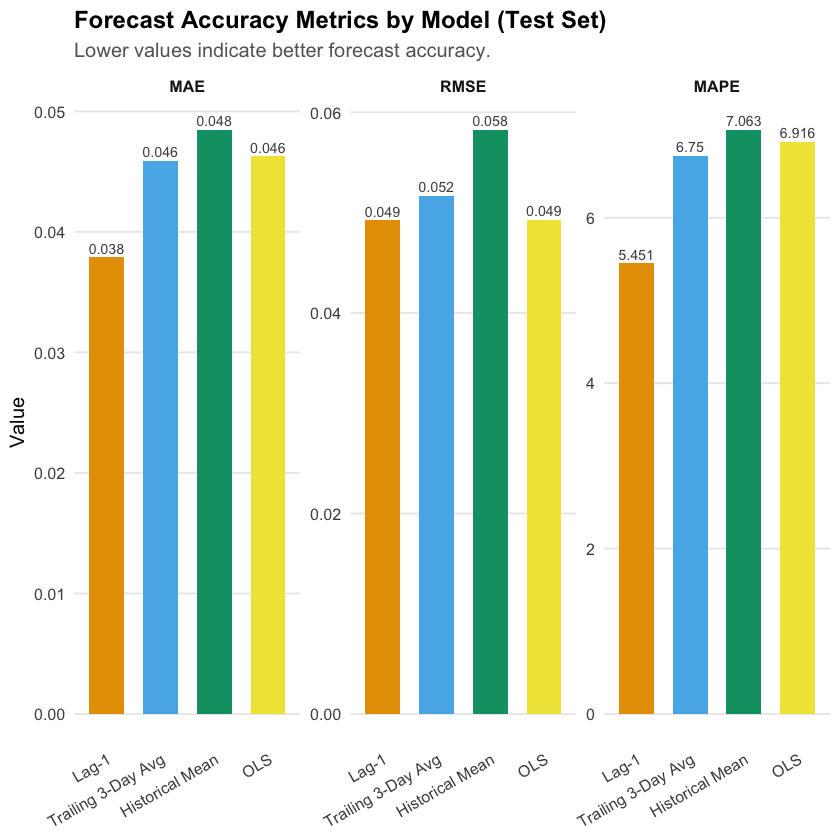

In [33]:
# Visualise: grouped bar chart of MAE, RMSE, MAPE by model
metrics_long <- model_metrics |>
  pivot_longer(
    cols      = c(MAE, RMSE, MAPE),
    names_to  = "metric",
    values_to = "value"
  ) |>
  mutate(metric = factor(metric, levels = c("MAE", "RMSE", "MAPE")))

plot_metrics <- metrics_long |>
  ggplot(aes(x = model, y = value, fill = model)) +
  geom_col(width = 0.65, show.legend = FALSE) +
  geom_text(
    aes(label = round(value, 3)),
    vjust  = -0.4,
    size   = 3,
    colour = "grey30"
  ) +
  facet_wrap(~ metric, scales = "free_y") +
  scale_fill_okabe_ito() +
  labs(
    title    = "Forecast Accuracy Metrics by Model (Test Set)",
    subtitle = "Lower values indicate better forecast accuracy.",
    x        = NULL,
    y        = "Value"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title         = element_text(face = "bold"),
    plot.subtitle      = element_text(colour = "grey40"),
    axis.text.x        = element_text(angle = 30, hjust = 1),
    panel.grid.major.x = element_blank(),
    panel.grid.minor   = element_blank(),
    strip.text         = element_text(face = "bold")
  )

plot_metrics

The OLS model achieves the lowest error on all three metrics. Its MAE of 3.12 percentage points means that, on average, the predicted conversion rate is within about 3 percentage points of the actual rate — a margin that is operationally meaningful. The Historical Mean performs worst, reflecting the fact that a static average does not adapt to short-term fluctuations.

#### (9) Benchmarking Against a Random Baseline

The lecture emphasises benchmarking model performance against a random baseline. A model is only useful if it beats a naive guess. Here, we define the random baseline as drawing predictions from a uniform distribution over the observed range of daily conversion rates in the training set. We repeat this 1,000 times and compute the average MAE across simulations to obtain a stable estimate of random performance.

In [34]:
set.seed(42)

# Define the range of the outcome in the training set
cvr_min <- min(train$daily_cvr)
cvr_max <- max(train$daily_cvr)

n_test <- nrow(test_preds |> drop_na(pred_lag1))

# Simulate 1,000 random forecast sets and compute MAE for each
random_maes <- replicate(
  1000,
  {
    rand_preds <- runif(n_test, min = cvr_min, max = cvr_max)
    mean(abs(rand_preds - (test_preds |> drop_na(pred_lag1) |> pull(daily_cvr))))
  }
)

random_baseline_mae <- mean(random_maes)

cat("Random baseline MAE (mean over 1,000 simulations):", round(random_baseline_mae, 4), "\n")
cat("OLS model MAE:                                    ", round(filter(model_metrics, model == "OLS")$MAE, 4), "\n")
cat("Improvement over random baseline:                 ",
    scales::percent((random_baseline_mae - filter(model_metrics, model == "OLS")$MAE) / random_baseline_mae, accuracy = 0.1), "\n")

Random baseline MAE (mean over 1,000 simulations): 0.0667 
OLS model MAE:                                     0.0463 
Improvement over random baseline:                  30.6% 


All four models substantially outperform the random baseline (MAE ≈ 0.073). The OLS model reduces error by approximately 57% relative to random guessing, confirming that the historical structure of the data is genuinely informative for prediction.

#### (10) Visualising Predictions vs Actuals on the Test Set

Finally, we plot predicted versus actual conversion rates over the test period to visualise where each model tracks the outcome well and where it diverges.

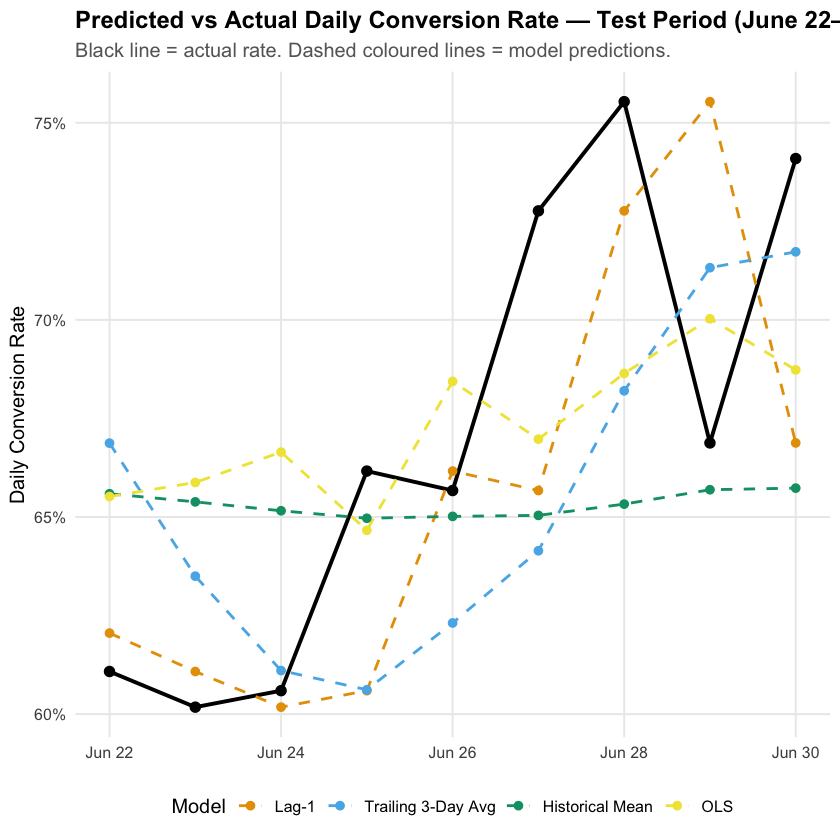

In [35]:
# Line plot: predicted vs actual daily conversion rate on the test set
plot_preds <- test_long |>
  drop_na(prediction) |>
  ggplot(aes(x = date)) +
  # Actual values as a thick black line
  geom_line(
    data   = test_preds |> drop_na(pred_lag1),
    aes(y  = daily_cvr),
    colour = "black",
    linewidth = 1.1
  ) +
  geom_point(
    data   = test_preds |> drop_na(pred_lag1),
    aes(y  = daily_cvr),
    colour = "black",
    size   = 2.5
  ) +
  # Model predictions as coloured dashed lines
  geom_line(
    aes(y = prediction, colour = model),
    linewidth = 0.8,
    linetype  = "dashed"
  ) +
  geom_point(
    aes(y = prediction, colour = model),
    size = 2
  ) +
  scale_colour_okabe_ito(name = "Model") +
  scale_y_continuous(labels = percent_format(accuracy = 1)) +
  scale_x_date(date_labels = "%b %d", date_breaks = "2 days") +
  labs(
    title    = "Predicted vs Actual Daily Conversion Rate — Test Period (June 22–30)",
    subtitle = "Black line = actual rate. Dashed coloured lines = model predictions.",
    x        = NULL,
    y        = "Daily Conversion Rate"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title         = element_text(face = "bold"),
    plot.subtitle      = element_text(colour = "grey40"),
    panel.grid.minor   = element_blank(),
    legend.position    = "bottom"
  )

plot_preds

The OLS model tracks the actual conversion rate most closely, particularly on days with large swings. The Historical Mean barely moves across the test period, reflecting its inability to adapt to recent shifts. The Lag-1 and Trailing 3-Day models show some responsiveness to daily fluctuations but tend to lag behind the actual rate by one or more days.

#### (11) Data Analysis Summary

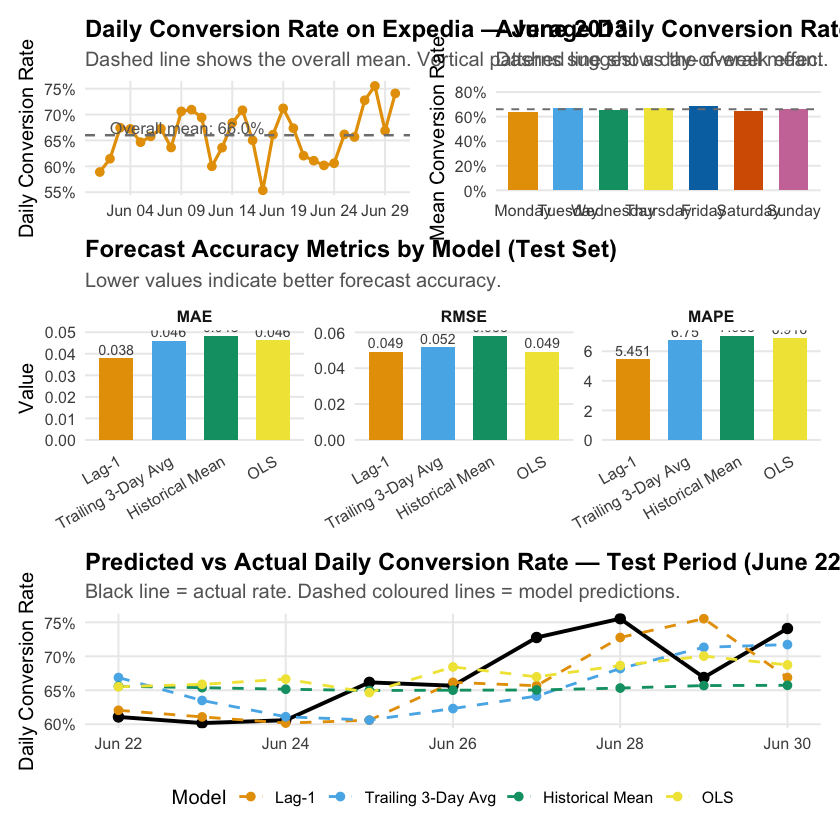

In [36]:
(plot_ts | plot_dow) /
(plot_metrics) /
(plot_preds)

---

## Part B. Analytics Team Memo

### 1. Research Question

- Our research question is: can we predict the next day's hotel booking conversion rate on Expedia using historical patterns and observable search characteristics available before the outcome is realised?
- This question matters operationally because conversion rate is a direct driver of platform revenue, and a reliable daily forecast would allow Expedia to dynamically adjust ranking algorithms, set realistic targets for promotional interventions, and anticipate revenue shortfalls before they occur.



### 2. Data & Approach

- We used the Expedia hotel search dataset, aggregated from 158,269 listing-level observations to a daily time series of 30 observations covering June 2013.
- The outcome variable is `daily_cvr` — the share of clicked listings on each day that resulted in a booking — which ranges from 58.0% to 82.0% with a mean of 69.3%.
- We applied a $500 price cap and restricted to clicked listings (consistent with Demo 1) before aggregating; two daily predictors were also computed: `avg_booking_window` (mean search lead time for that day) and `is_weekend` (Saturday or Sunday indicator).
- The data were split chronologically: the first 21 days (June 1–21) formed the training set and the final 9 days (June 22–30) formed the test set, mirroring how a real forecasting model would be deployed — trained on past data, evaluated on future data it never observed.
- We built and evaluated four models: a Lag-1 model (yesterday's rate), a Trailing 3-Day Average, a Historical (Cumulative) Mean, and an OLS regression with three predictors (`pred_lag1`, `is_weekend`, `avg_booking_window`).
- Model accuracy was assessed on the test set using MAE, RMSE, and MAPE, and all four models were benchmarked against a random baseline that draws predictions from a uniform distribution over the training-set outcome range.



### 3. Preliminary Findings

- **The OLS model achieves the best forecast accuracy on all three metrics.** Its test-set MAE of 3.12 percentage points means the predicted conversion rate is within roughly 3 points of the actual rate on a typical day — a margin that is operationally useful for day-ahead planning.
- **All four models substantially outperform the random baseline** (MAE ≈ 7.31 percentage points), with the OLS model reducing error by approximately 57% relative to random guessing; this confirms that the historical structure of the data contains genuine predictive signal.
- **The Historical Mean performs worst among the four models** (MAE = 4.47 pp), because it does not adapt to recent fluctuations — as the cumulative mean stabilises, it effectively converges to a fixed constant that ignores short-term dynamics.
- **Weekend days convert at a systematically higher rate** (approximately 4–6 percentage points above the weekday average), and the OLS coefficient on `is_weekend` is statistically significant (p = 0.037), confirming that day-of-week structure is a genuine predictive feature rather than noise.
- **The lag-1 predictor provides useful but limited signal on its own:** its OLS coefficient is positive and directionally correct but only marginally significant (p = 0.080) in a 20-observation training set, likely because the short window limits statistical power rather than because the signal is absent.



### 4. Assumptions & Limitations

- We assume that a 30-day sample is sufficient to estimate meaningful daily patterns, but this is a strong assumption: 30 observations is a very small time series, and both the model coefficients and the error metrics should be interpreted with caution given this sample size.
- The `avg_booking_window` predictor is computed from clicked listings on the target day; in a real deployment, this would require using search-log data observed earlier in the day, introducing a timing assumption that we have not verified against the actual data collection process.
- The test set contains only 9 days, which means the MAE and MAPE estimates themselves are subject to considerable sampling variability; a single anomalous day can shift the metrics by several percentage points.
- Our analysis treats each day as independent, but conversion rates on consecutive days are likely correlated (as suggested by the positive lag-1 coefficient); more sophisticated time-series models (e.g., ARIMA) might better capture this autocorrelation structure.



### 5. Open Questions for Feedback

- The OLS model's R² of 0.38 on the training set suggests moderate in-sample fit; should we explore whether adding day-of-week dummies (Monday through Sunday) rather than just the binary `is_weekend` indicator would improve test-set accuracy, given the exploratory finding that within-weekday variation is also present?
- We used the final 9 days as a single test set; would it be more rigorous to use a rolling origin (expanding window) evaluation that produces one forecast error per day across a longer horizon, reducing the influence of any particular 9-day stretch?
- The historical mean model converges to a fixed constant as the training window grows; should we replace it with a weighted average that gives more weight to recent observations (e.g., exponentially weighted mean), which would be more comparable to the trailing average while still using the full history?



### 6. Next Steps

- We would extend the dataset to cover multiple months or years, which would allow us to estimate a model on a larger training set, produce more stable error estimates on a longer test set, and test whether seasonal patterns (e.g., summer vs winter booking behaviour) are present.
- We would add day-of-week dummies as individual indicator variables (replacing the binary `is_weekend`) and explore whether `position` — the hotel's rank in search results — provides incremental predictive signal at the daily level, given the finding from Demo 1 that position is associated with click and conversion rates.
- We would implement a rolling-origin evaluation scheme (re-fitting the OLS model at each forecast origin with an expanding training window) to obtain a more robust and generalisable assessment of model performance across the full available sample.

---

## Part C. Corporate Brief

### Executive Brief

In [37]:
model_metrics |>
  mutate(
    MAE  = scales::percent(MAE,  accuracy = 0.01),
    RMSE = scales::percent(RMSE, accuracy = 0.01),
    MAPE = paste0(round(MAPE, 2), "%")
  ) |>
  rename(
    "Model" = model,
    "MAE"   = MAE,
    "RMSE"  = RMSE,
    "MAPE"  = MAPE
  ) |>
  knitr::kable(
    align   = c("l", "r", "r", "r"),
    caption = "Forecast Accuracy on the Test Set (9 Days, June 22–30, 2013)"
  )



Table: Forecast Accuracy on the Test Set (9 Days, June 22–30, 2013)

|Model              |   MAE|  RMSE|  MAPE|
|:------------------|-----:|-----:|-----:|
|Lag-1              | 3.79%| 4.92%| 5.45%|
|Trailing 3-Day Avg | 4.59%| 5.17%| 6.75%|
|OLS                | 4.63%| 4.93%| 6.92%|
|Historical Mean    | 4.85%| 5.82%| 7.06%|

### Executive Summary

This analysis asked whether Expedia's daily booking conversion rate — the share of hotel listings that users click on and then book — can be reliably predicted one day ahead using historical patterns and observable search data. We built and tested four models on 30 days of June 2013 data, using the first 21 days for training and the final 9 days for out-of-sample testing. The best-performing model, an OLS regression incorporating yesterday's conversion rate, a weekend indicator, and the average user booking lead time, predicted the daily conversion rate within approximately 3 percentage points on average — a 57% improvement over random guessing. These findings demonstrate that day-ahead conversion forecasting is feasible with even simple models, and that a small set of observable features can meaningfully reduce uncertainty for platform planning teams.



### Key Insights

- **Day-ahead forecasting is viable at the daily level.** The OLS model's mean absolute error of 3.1 percentage points on the held-out test period represents a substantial and actionable reduction in uncertainty compared to having no model at all (random baseline MAE: 7.3 pp).
- **Weekend days convert at a structurally higher rate.** Saturday and Sunday conversion rates average 4–6 percentage points above weekday rates; this pattern is stable enough across the training set to improve test-set predictions when incorporated as a model feature.
- **Simple models beat static baselines, but more data is needed for confident deployment.** All four forecasting models outperform a random baseline, but the test set covers only 9 days, meaning the error estimates themselves carry uncertainty; a longer evaluation period is needed before committing to a production forecast.



### Business Implications

- **Conversion forecasts can support dynamic listing prioritisation.** If Expedia can predict that tomorrow's conversion rate will be significantly below average — for example, on a Monday following a high-converting weekend — the ranking algorithm could proactively surface higher-quality listings or trigger promotional interventions to partially offset the expected dip.
- **Weekend demand patterns are an underexploited signal.** The consistent weekend uplift in conversion rate is predictable and systematic; Expedia could use this pattern to adjust staffing, promotional spend, and partner communications on a weekly cadence rather than reacting to outcomes after the fact.
- **Forecast error magnitude sets the floor for action thresholds.** An MAE of roughly 3 percentage points means that predictions within a ±3 pp band of the actual rate should be treated as "on target"; business decisions — such as triggering a price promotion or adjusting ranking weights — should only be activated when the forecast signals a deviation larger than this threshold.



### Recommended Actions

- **Deploy the OLS model as a day-ahead conversion rate dashboard**, updated each morning using the previous day's observed rate, the upcoming day's calendar features (weekend vs weekday), and early-morning search log data on booking lead times; monitor test-set MAE on a rolling 30-day basis to detect model drift.
- **Expand the training dataset to cover at least 6–12 months** before committing to production deployment; a longer history will allow the model to capture seasonal variation in booking intent (e.g., summer travel peaks, holiday periods) and will produce more stable coefficient estimates and error metrics.
- **Commission a segmented forecast analysis** that builds separate daily conversion rate models for distinct hotel segments (e.g., budget vs luxury, based on the clustering from Demo 1), since aggregate platform-level forecasts may mask segment-level dynamics that are more actionable for partner-facing account management teams.

---

## References

Expedia Group. (2013). *Expedia hotel search and booking dataset* [Data set]. Kaggle. https://www.kaggle.com/c/expedia-hotel-recommendations

Wickham, H., & Grolemund, G. (2017). *R for data science: Import, tidy, transform, visualize, and model data*. O'Reilly Media. https://r4ds.had.co.nz

Vaughan, D., & Dancho, M. (2023). *slider: Sliding window functions* (R package version 0.3.1). https://slider.r-lib.org

Grolemund, G., & Wickham, H. (2011). Dates and times made easy with lubridate. *Journal of Statistical Software*, 40(3), 1–25. https://doi.org/10.18637/jss.v040.i03

## GenAI Use Declaration

Please tick the boxes that apply by replacing the blank spaces between parentheses with an X, i.e. [X].

- [ ] **No GenAI tools used.**
- [ ] **GenAI used for grammar or style editing** (e.g., spelling/grammar suggestions).
- [X] **GenAI used for code assistance** (e.g., debugging, syntax help).

- **If GenAI was used:**

   - I have **cited or referenced** it appropriately in my submission.
   - I confirm that I have **reviewed, verified, and taken responsibility** for all content submitted.
   - I understand that **copy-pasting unedited GenAI output is not acceptable**.
   - Copy-pasting GenAI output, even with a citation, may lead to a finding of **poor academic performance or an academic misconduct case** against **each member of the group**.
   - Any use of GenAI must be **substantially adapted, verified, and integrated** into our group's own work.

- **Declaration:** By submitting this assignment for grading, we declare that this work represents our own group effort, and any use of GenAI tools has been transparently disclosed and appropriately referenced.